
# Lower Limb Movement Sensing

This notebook contains the processing and visualization of the strain sensor measurements recorded during the laboratory 2. 






# Lab 2a - Sensor Setup & Data Collection

## 1.1 Setup & Positioning of the sensors


- Two EMG sensors were placed on the quadriceps and calf muscles to measure muscle activity. 

- A resistive strain sensor was positioned across the knee to monitor knee bending.

**Note:** See images in the report


## 1.2 Knee Bending and Strain Sensor Response




In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Fixed Resistor
R1 = 10000  

# Maximum value of 10-bit ADC
max_adc = 1023 

# Convert ADC values to sensor resistance
def adc_to_resistance(adc):
    return R1 * adc / (max_adc - adc)

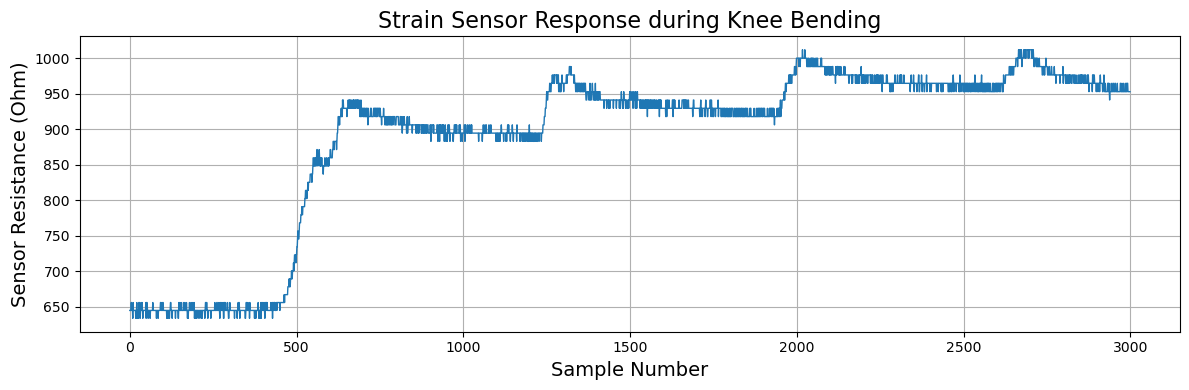

In [2]:
# Load knee bending data
adc_knee = np.loadtxt("ex1.2_check_1.txt", delimiter=",")

# Extract sensor signals
adc_strain = adc_knee[:3000, 0]
emg_quad = adc_knee[:, 1]
emg_calf = adc_knee[:, 2]

# Convert ADC values to sensor resistance
resistance_knee = adc_to_resistance(adc_strain)

# Plot
plt.figure(figsize=(12, 4))
plt.plot(resistance_knee, linewidth=1)

plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("Sensor Resistance (Ohm)", fontsize=14)
plt.title("Strain Sensor Response during Knee Bending", fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()

## Note
1 second == 250 samples


## 1.3 RAW EMG Recordings

### Quad Recording

All three channels from `ex1.3_quad_20sec.txt`, plotted as raw ADC values at 250 Hz.


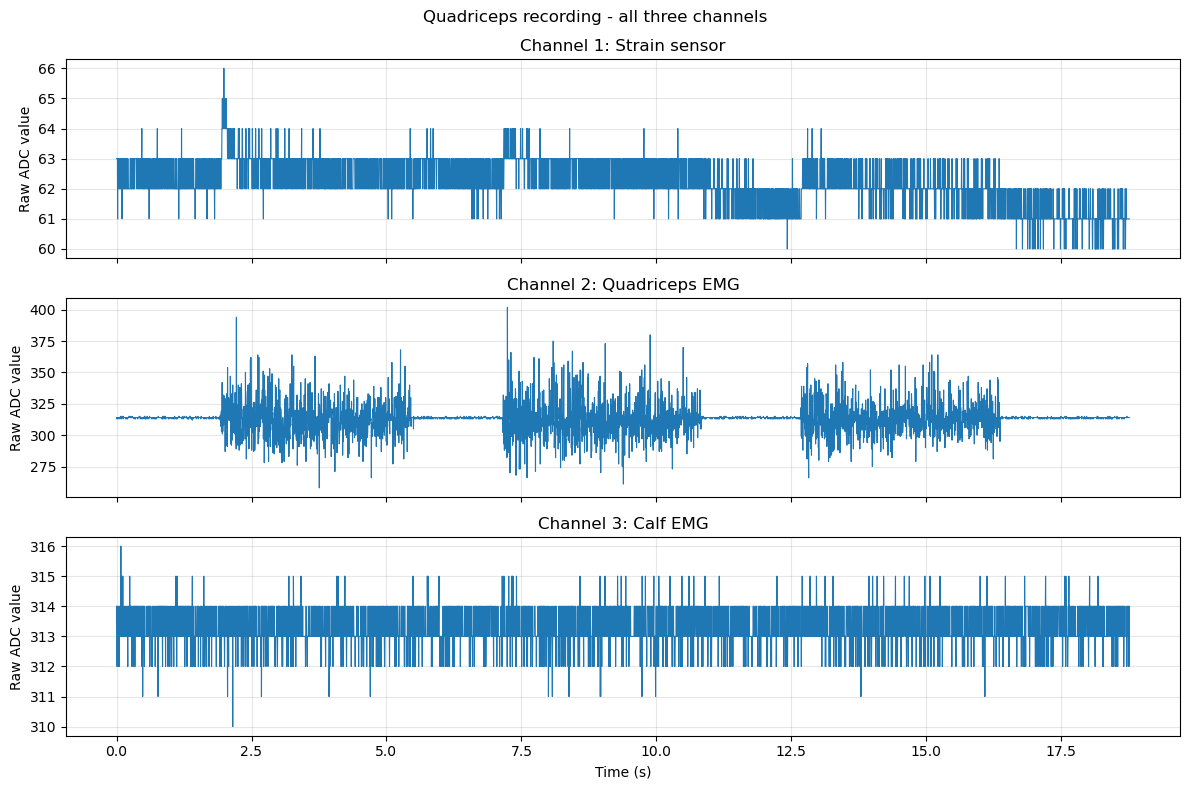

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Columns: strain sensor, quadriceps EMG, calf EMG (raw ADC values).
quad_data = np.loadtxt("ex1.3_quad_20sec.txt", delimiter=",")
sampling_rate = 250  # Hz: 250 samples per second
time_s = np.arange(quad_data.shape[0]) / sampling_rate

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
channel_names = ["Strain sensor", "Quadriceps EMG", "Calf EMG"]
for channel, (ax, name) in enumerate(zip(axes, channel_names)):
    ax.plot(time_s, quad_data[:, channel], linewidth=0.8)
    ax.set_title(f"Channel {channel + 1}: {name}")
    ax.set_ylabel("Raw ADC value")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (s)")
fig.suptitle("Quadriceps recording - all three channels")
fig.tight_layout()
plt.show()


## Calf recording

All three channels from `ex1.3_calve_20sec_clean.txt`, plotted as raw ADC values at 250 Hz.


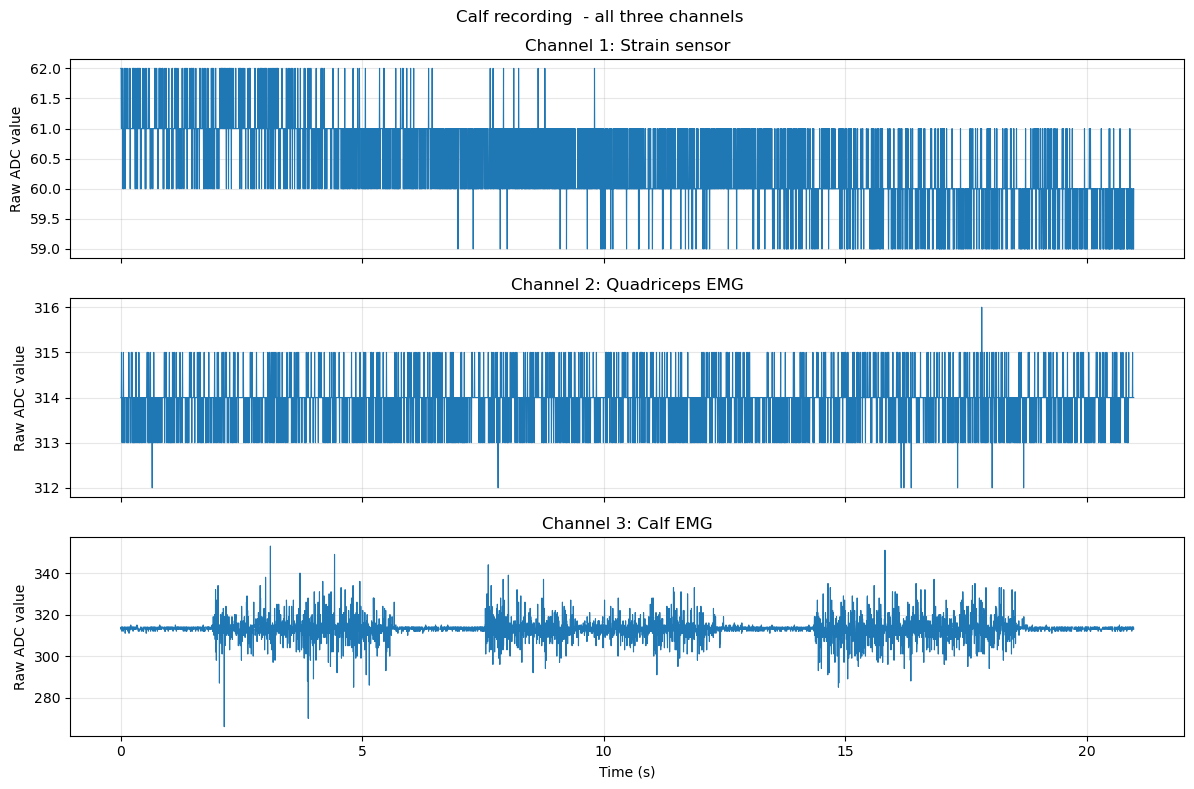

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Columns: strain sensor, quadriceps EMG, calf EMG (raw ADC values).
calf_data = np.loadtxt("ex1.3_calve_20sec_clean.txt", delimiter=",")
sampling_rate = 250  # Hz: 250 samples per second
time_s = np.arange(calf_data.shape[0]) / sampling_rate

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
channel_names = ["Strain sensor", "Quadriceps EMG", "Calf EMG"]
for channel, (ax, name) in enumerate(zip(axes, channel_names)):
    ax.plot(time_s, calf_data[:, channel], linewidth=0.8)
    ax.set_title(f"Channel {channel + 1}: {name}")
    ax.set_ylabel("Raw ADC value")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (s)")
fig.suptitle("Calf recording  - all three channels")
fig.tight_layout()
plt.show()


## Knee bending recording

All three channels from `ex1.2_check_1.txt`, plotted as raw ADC values at 250 Hz.


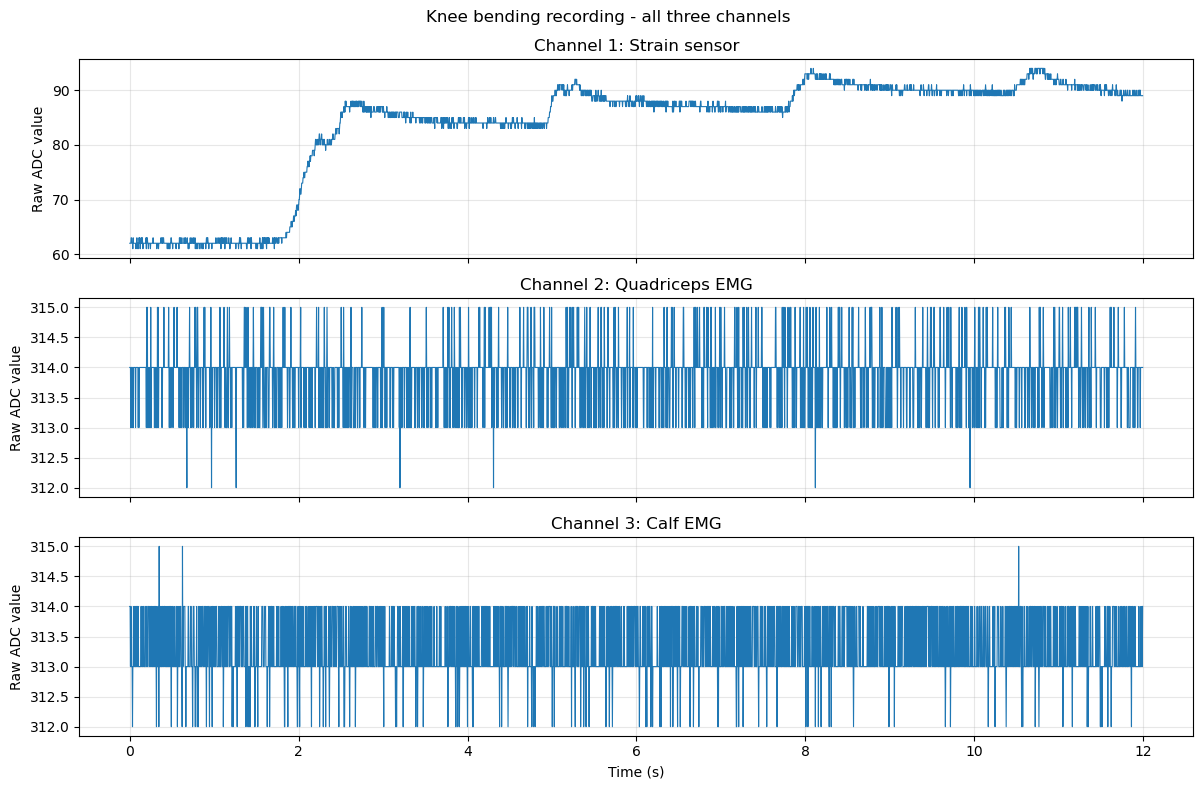

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Columns: strain sensor, quadriceps EMG, calf EMG (raw ADC values).
knee_data = np.loadtxt("ex1.2_check_1.txt", delimiter=",")
sampling_rate = 250  # Hz: 250 samples per second
time_s = np.arange(knee_data.shape[0]) / sampling_rate

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
channel_names = ["Strain sensor", "Quadriceps EMG", "Calf EMG"]
for channel, (ax, name) in enumerate(zip(axes, channel_names)):
    ax.plot(time_s[:3000], knee_data[:3000, channel], linewidth=0.8)
    ax.set_title(f"Channel {channel + 1}: {name}")
    ax.set_ylabel("Raw ADC value")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (s)")
fig.suptitle("Knee bending recording - all three channels")
fig.tight_layout()
plt.show()


### In case one wanted to see only the calf channel and the quad channel in the respective recordings, the code down here allows to do it

In [6]:
"""
# Load raw EMG test data
adc_quad = np.loadtxt("ex1.3_quad_20sec.txt", delimiter=",")
adc_calve = np.loadtxt("ex1.3_calve_20sec_clean.txt", delimiter=",")

# Extract raw EMG signals
emg_quad = adc_quad[:,1]
emg_calve = adc_calve[:,2]

# Plot quad EMG
plt.figure(figsize=(10, 4))
plt.plot(emg_quad, linewidth=0.8)
plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("Raw EMG signals", fontsize=14)
plt.title("Quadriceps Muscle Activity", fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot calf EMG
plt.figure(figsize=(10, 4))
plt.plot(emg_calve, linewidth=0.8)
plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("Raw EMG signals", fontsize=14)
plt.title("Calf Muscle Activity", fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()
"""

'\n# Load raw EMG test data\nadc_quad = np.loadtxt("ex1.3_quad_20sec.txt", delimiter=",")\nadc_calve = np.loadtxt("ex1.3_calve_20sec_clean.txt", delimiter=",")\n\n# Extract raw EMG signals\nemg_quad = adc_quad[:,1]\nemg_calve = adc_calve[:,2]\n\n# Plot quad EMG\nplt.figure(figsize=(10, 4))\nplt.plot(emg_quad, linewidth=0.8)\nplt.xlabel("Sample Number", fontsize=14)\nplt.ylabel("Raw EMG signals", fontsize=14)\nplt.title("Quadriceps Muscle Activity", fontsize=16)\nplt.grid(True)\nplt.tight_layout()\nplt.show()\n\n# Plot calf EMG\nplt.figure(figsize=(10, 4))\nplt.plot(emg_calve, linewidth=0.8)\nplt.xlabel("Sample Number", fontsize=14)\nplt.ylabel("Raw EMG signals", fontsize=14)\nplt.title("Calf Muscle Activity", fontsize=16)\nplt.grid(True)\nplt.tight_layout()\nplt.show()\n'

# Lab 2b - Data Processing


## Feature extraction

In [7]:
def remove_outliers(s, window, thresh=2.5):
    # Calculate rolling mean and standard deviation over the specified window
    roll = s.rolling(window=window, min_periods=1, center=True)
    avg = roll.mean() # Rolling mean
    std = roll.std(ddof=0) # Rolling standard deviation (with N as denominator)
    # Calculate z-scores by subtracting the rolling mean and dividing by rolling std
    z = s.sub(avg).div(std)
    # Create a mask identifying values within the acceptable z-score threshold
    m = z.between(-thresh, thresh)
    # Replace outliers (values outside threshold) with the rolling mean
    return s.where(m, avg)

In [ ]:
def rms(x):
    return np.sqrt(np.mean(x**2))

def waveformlength(x):
    return np.sum(np.abs(np.diff(x)))

def aryule(x, order):
    """
    Estimate AR model coefficients using Yule-Walker method
    Parameters:
    x (array-like): The time series data
    order (int): The order of the AR model
    Returns:
    a: The estimated AR coefficients
    """
    x = np.asarray(x)
    n = len(x)
    # Compute autocorrelation
    r = np.correlate(x, x, mode='full')[n-1:]
    r = r[:order+1] / n
    # Initialize
    a = np.zeros(order)
    e = np.zeros(order+1)
    k = np.zeros(order)
    e[0] = r[0]
    # Levinson-Durbin recursion
    for i in range(order):
        # Compute reflection coefficient
        k[i] = (r[i+1] - np.sum(a[:i] * r[i:0:-1])) / e[i]
        # Update AR coefficients
        a[i] = k[i]
        if i > 0:
            a[:i] = a[:i] - k[i] * a[i-1::-1]
        # Update prediction error
        e[i+1] = (1 - k[i]**2) * e[i]
    return -a

def feature_extraction(df, window_size):
    features = []
    labels = []
    label = df.iloc[0, 3] # Extract label from 4th column, constant per df
    for i in range(window_size, len(df), 1): # step +window size give overlap
        win = df.iloc[i-window_size:i] ##VERIFY
        emg1 = win["Quadriceps EMG"].values # Quad
        emg2 = win["Calf EMG"].values # Calf
        strain = win["Strain Sensor"].values
        rms1 = rms(emg1)
        wl1 = waveformlength(emg1)
        ar1 = aryule(emg1, order=4)
        rms2 = rms(emg2)
        wl2 = waveformlength(emg2)
        ar2 = aryule(emg2, order=4)
        rms_strain = rms(strain)
        feat = np.concatenate([[rms1, wl1] + list(ar1), [rms2, wl2] + list(ar2), [rms_strain]])
        features.append(feat)
        labels.append(label)
    return np.array(features), np.array(labels)


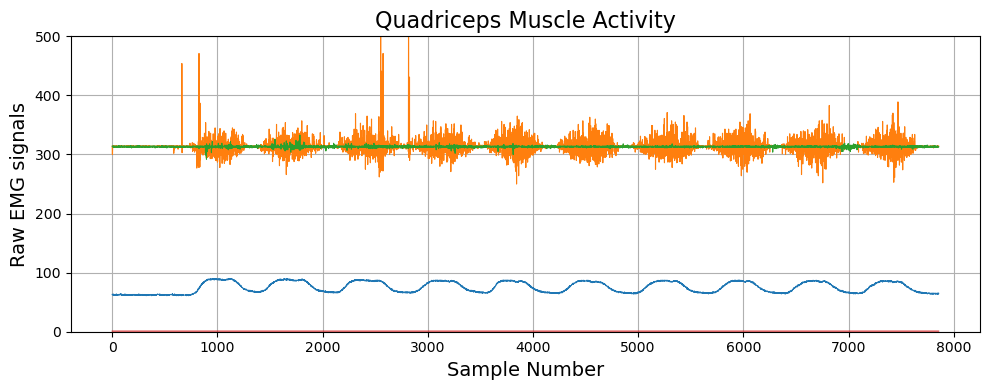

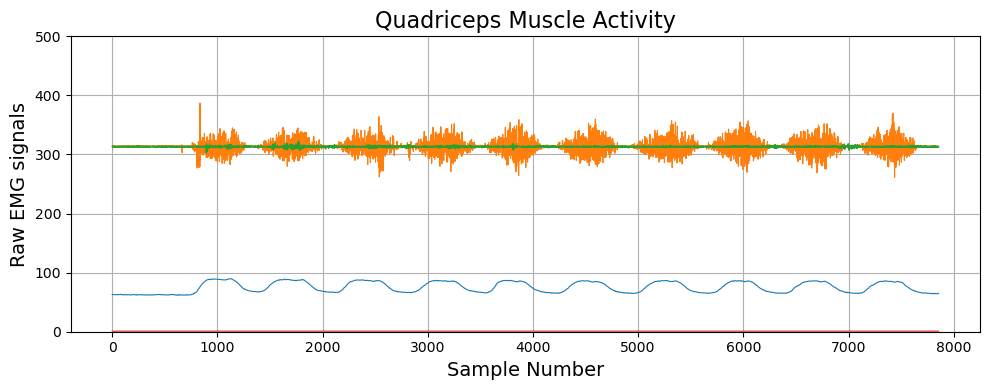

       Strain Sensor  Quadriceps EMG  Calf EMG  Activity
0          59.999229      312.840000     313.0       3.0
1          59.503584      298.000000     314.0       3.0
2          59.083575      293.000000     315.0       3.0
3          58.791150      271.000000     314.0       3.0
4          58.641534      265.000000     314.0       3.0
...              ...             ...       ...       ...
13523      56.947690      314.000000     312.0       3.0
13524      56.953639      314.000000     314.0       3.0
13525      56.969809      315.000000     313.0       3.0
13526      56.988532      314.000000     314.0       3.0
13527      57.005840      313.923077     313.0       3.0

[13528 rows x 4 columns]


In [33]:
import pandas as pd
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt

df_squat = pd.read_csv("ex1.4_squat_10times_2.txt", header=None)
df_squat.dropna()
df_squat_4col = np.column_stack((df_squat, np.ones(df_squat.shape[0])))
df_squat_4col = pd.DataFrame(df_squat_4col, columns=["Strain Sensor", "Quadriceps EMG", "Calf EMG", "Activity"])
#print(df_squat_4col)
# Plot test(outliers not removed)
plt.figure(figsize=(10, 4))
plt.plot(df_squat_4col, linewidth=0.8)
plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("Raw EMG signals", fontsize=14)
plt.title("Quadriceps Muscle Activity", fontsize=16)
plt.grid(True)
plt.ylim(0,500)
plt.tight_layout()
plt.show()

fs = 100 #250 
b, a = signal.butter(4, 10, btype="low", fs=fs)

df_squat_4col["Strain Sensor"] = signal.filtfilt(b, a, df_squat_4col["Strain Sensor"])
df_squat_4col.iloc[:, 1:3] = df_squat_4col.iloc[:, 1:3].apply(lambda x: remove_outliers(x, window=50), axis=0)

# Plot test (with outliers removed)
plt.figure(figsize=(10, 4))
plt.plot(df_squat_4col, linewidth=0.8)
plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("Raw EMG signals", fontsize=14)
plt.title("Quadriceps Muscle Activity", fontsize=16)
plt.ylim(0,500)
plt.grid(True)
plt.tight_layout()
plt.show()

df_stand = pd.read_csv("ex1.4_stand_60sec_1.txt", header=None)
df_stand.dropna()
df_stand_4col = np.column_stack((df_stand, np.zeros(df_stand.shape[0])))
df_stand_4col = pd.DataFrame(df_stand_4col, columns=["Strain Sensor", "Quadriceps EMG", "Calf EMG", "Activity"])
df_stand_4col["Strain Sensor"] = signal.filtfilt(b, a, df_stand_4col["Strain Sensor"])
df_stand_4col.iloc[:, 1:3] = df_stand_4col.iloc[:, 1:3].apply(lambda x: remove_outliers(x, window=50), axis=0)

df_toeraise = pd.read_csv("ex1.4_toeraise_1.txt", header=None)
df_toeraise.dropna()
df_toeraise_4col = np.column_stack((df_toeraise, 3*np.ones(df_toeraise.shape[0])))
df_toeraise_4col = pd.DataFrame(df_toeraise_4col, columns=["Strain Sensor", "Quadriceps EMG", "Calf EMG", "Activity"])
df_toeraise_4col["Strain Sensor"] = signal.filtfilt(b, a, df_toeraise_4col["Strain Sensor"])
df_toeraise_4col.iloc[:, 1:3] = df_toeraise_4col.iloc[:, 1:3].apply(lambda x: remove_outliers(x, window=50), axis=0)


df_kickback= pd.read_csv("ex1.4_kickback_1.txt", header=None)
df_kickback.dropna()
df_kickback_4col = np.column_stack((df_kickback, 4*np.ones(df_kickback.shape[0])))
df_kickback_4col = pd.DataFrame(df_kickback_4col, columns=["Strain Sensor", "Quadriceps EMG", "Calf EMG", "Activity"])
df_kickback_4col["Strain Sensor"] = signal.filtfilt(b, a, df_kickback_4col["Strain Sensor"])
df_kickback_4col.iloc[:, 1:3] = df_kickback_4col.iloc[:, 1:3].apply(lambda x: remove_outliers(x, window=50), axis=0)

df_kneeraise = pd.read_csv("ex1.4_kneeraise_1.txt", header=None)
df_kneeraise.dropna()
df_kneeraise_4col = np.column_stack((df_kneeraise, 5*np.ones(df_kneeraise.shape[0])))
df_kneeraise_4col = pd.DataFrame(df_kneeraise_4col, columns=["Strain Sensor", "Quadriceps EMG", "Calf EMG", "Activity"])
df_kneeraise_4col["Strain Sensor"] = signal.filtfilt(b, a, df_kneeraise_4col["Strain Sensor"])
df_kneeraise_4col.iloc[:, 1:3] = df_kneeraise_4col.iloc[:, 1:3].apply(lambda x: remove_outliers(x, window=50), axis=0)


print(df_toeraise_4col)

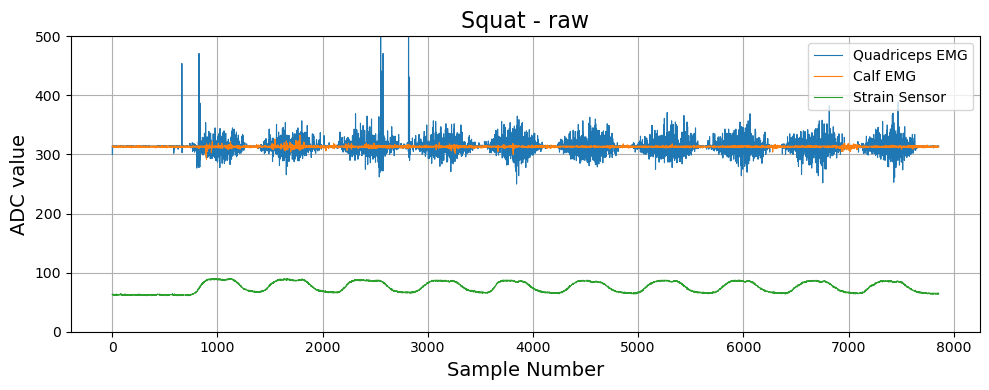

Squat: rows 7858 | replaced outliers per channel:
 Quadriceps EMG    187
Calf EMG          141
dtype: int64


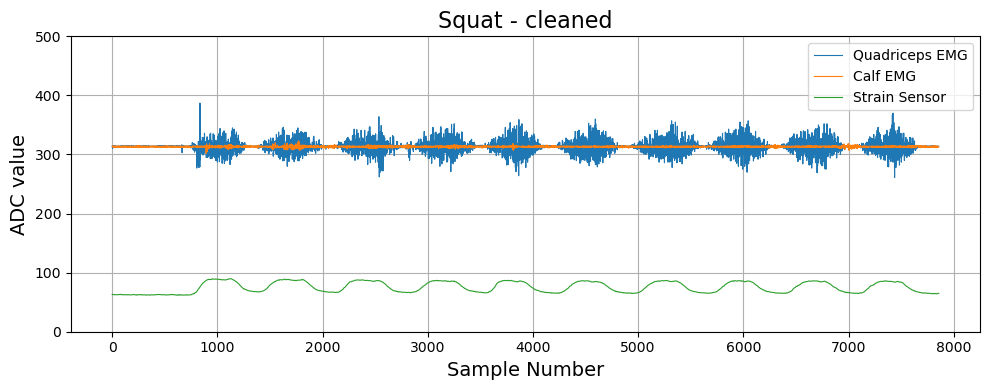

       Quadriceps EMG  Calf EMG  Strain Sensor  Activity
0          312.840000     313.0      59.999229       2.0
1          298.000000     314.0      59.503584       2.0
2          293.000000     315.0      59.083575       2.0
3          271.000000     314.0      58.791150       2.0
4          265.000000     314.0      58.641534       2.0
...               ...       ...            ...       ...
13523      314.000000     312.0      56.947690       2.0
13524      314.000000     314.0      56.953639       2.0
13525      315.000000     313.0      56.969809       2.0
13526      314.000000     314.0      56.988532       2.0
13527      313.923077     313.0      57.005840       2.0

[13528 rows x 4 columns]


In [34]:
# Linus changes: swap the order of the columns to match the required order: Quadriceps EMG, Calf EMG, Strain Sensor, Activity

import pandas as pd
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt

cols = ["Quadriceps EMG", "Calf EMG", "Strain Sensor", "Activity"]   # required column order
emg_cols = ["Quadriceps EMG", "Calf EMG"]

fs = 100 #250 
b, a = signal.butter(4, 10, btype="low", fs=fs)

# ---------------- Squat (label 1) ----------------
df_squat = pd.read_csv("ex1.4_squat_10times_2.txt", header=None)     # header=None: keep first sample
df_squat = df_squat.dropna()                                         # remove NaN rows
df_squat_4col = np.column_stack((df_squat.iloc[:, [1, 2, 0]], np.ones(df_squat.shape[0])))   # quad, calf, strain
df_squat_4col = pd.DataFrame(df_squat_4col, columns=cols)
raw_squat = df_squat_4col.copy()                                     # keep raw copy to compare

# Plot raw
plt.figure(figsize=(10, 4))
plt.plot(df_squat_4col.iloc[:, :3], linewidth=0.8)
plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("ADC value", fontsize=14)
plt.title("Squat - raw", fontsize=16)
plt.grid(True)
plt.ylim(0,500)
plt.legend(["Quadriceps EMG", "Calf EMG", "Strain Sensor"], loc="upper right")
plt.tight_layout()
plt.show()

df_squat_4col["Strain Sensor"] = signal.filtfilt(b, a, df_squat_4col["Strain Sensor"])
df_squat_4col[emg_cols] = df_squat_4col[emg_cols].apply(lambda x: remove_outliers(x, window=50), axis=0)
print("Squat: rows", len(df_squat_4col), "| replaced outliers per channel:\n",
      (raw_squat[emg_cols] != df_squat_4col[emg_cols]).sum())

# Plot cleaned
plt.figure(figsize=(10, 4))
plt.plot(df_squat_4col.iloc[:, :3], linewidth=0.8)
plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("ADC value", fontsize=14)
plt.title("Squat - cleaned", fontsize=16)
plt.ylim(0,500)
plt.grid(True)
plt.legend(["Quadriceps EMG", "Calf EMG", "Strain Sensor"], loc="upper right")
plt.tight_layout()
plt.show()

# ---------------- Stand (label 0) ----------------
df_stand = pd.read_csv("ex1.4_stand_60sec_1.txt", header=None).dropna()
df_stand_4col = np.column_stack((df_stand.iloc[:, [1, 2, 0]], np.zeros(df_stand.shape[0])))
df_stand_4col = pd.DataFrame(df_stand_4col, columns=cols)
df_stand_4col["Strain Sensor"] = signal.filtfilt(b, a, df_stand_4col["Strain Sensor"])
df_stand_4col[emg_cols] = df_stand_4col[emg_cols].apply(lambda x: remove_outliers(x, window=50), axis=0)

# ---------------- Toe raise (label 2) ----------------
df_toeraise = pd.read_csv("ex1.4_toeraise_1.txt", header=None).dropna()
df_toeraise_4col = np.column_stack((df_toeraise.iloc[:, [1, 2, 0]], 2*np.ones(df_toeraise.shape[0])))
df_toeraise_4col = pd.DataFrame(df_toeraise_4col, columns=cols)
df_toeraise_4col["Strain Sensor"] = signal.filtfilt(b, a, df_toeraise_4col["Strain Sensor"])
df_toeraise_4col[emg_cols] = df_toeraise_4col[emg_cols].apply(lambda x: remove_outliers(x, window=50), axis=0)

print(df_toeraise_4col)

# ---------------- Kick back (label 3) ----------------
df_kickback = pd.read_csv("ex1.4_kickback_1.txt", header=None).dropna()
df_kickback_4col = np.column_stack((df_kickback.iloc[:, [1, 2, 0]], 3*np.ones(df_kickback.shape[0])))
df_kickback_4col = pd.DataFrame(df_kickback_4col, columns=cols)
df_kickback_4col["Strain Sensor"] = signal.filtfilt(b, a, df_kickback_4col["Strain Sensor"])
df_kickback_4col[emg_cols] = df_kickback_4col[emg_cols].apply(lambda x: remove_outliers(x, window=50), axis=0)

# ---------------- Knee raise (label 4) ----------------
df_kneeraise = pd.read_csv("ex1.4_kneeraise_1.txt", header=None).dropna()
df_kneeraise_4col = np.column_stack((df_kneeraise.iloc[:, [1, 2, 0]], 4*np.ones(df_kneeraise.shape[0])))
df_kneeraise_4col = pd.DataFrame(df_kneeraise_4col, columns=cols)
df_kneeraise_4col["Strain Sensor"] = signal.filtfilt(b, a, df_kneeraise_4col["Strain Sensor"])
df_kneeraise_4col[emg_cols] = df_kneeraise_4col[emg_cols].apply(lambda x: remove_outliers(x, window=50), axis=0)

In [37]:
import numpy as np
from sklearn.model_selection import train_test_split
#train_df, test_df = train_test_split(df_squat_4col, train_size=0.8, random_state=42, shuffle=False)
window_size=100
activity_frames=[df_stand_4col, df_squat_4col, df_toeraise_4col, df_kickback_4col, df_kneeraise_4col]
train_features_all = []
test_features_all = []
train_labels_all = []
test_labels_all = []
for activity_df in activity_frames:
    #activity_frames is a list of data frames, each containing one activity
    train_df, test_df = train_test_split(activity_df, train_size=0.8, random_state=42, shuffle=False)
    train_feat, y_train = feature_extraction(train_df, window_size=window_size)
    test_feat, y_test = feature_extraction(test_df, window_size=window_size)
    train_features_all.append(train_feat)
    test_features_all.append(test_feat)
    train_labels_all.append(y_train)
    test_labels_all.append(y_test)
#train_features_per_activity = train_features_all.copy()
train_features_all = np.vstack(train_features_all)
test_features_all = np.vstack(test_features_all)
train_labels_all = np.hstack(train_labels_all)
test_labels_all = np.hstack(test_labels_all)


In [12]:
print(train_features_all.shape)
print(train_labels_all.shape)
print(test_features_all.shape)
print(test_labels_all.shape)
print(test_labels_all[45])

(37586, 13)
(37586,)
(9024, 13)
(9024,)
0.0


## Q2

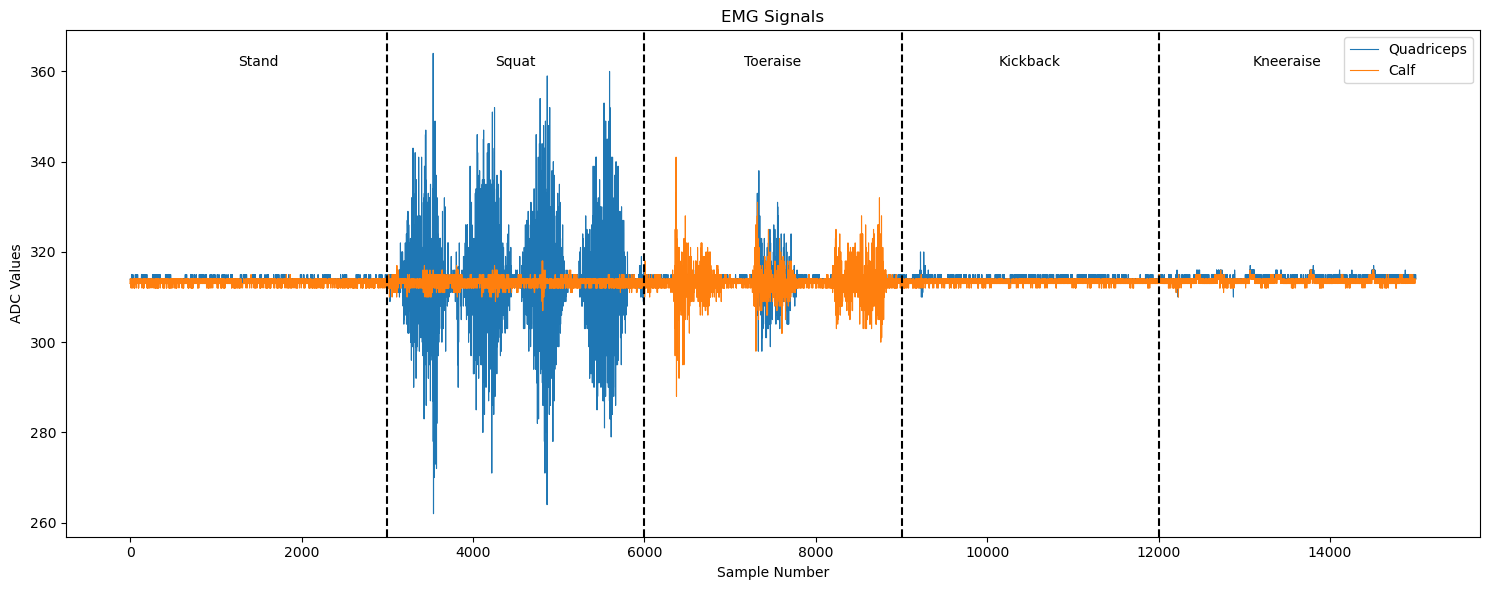

In [23]:
activity_names = ["Stand", "Squat", "Toeraise", "Kickback", "Kneeraise"]

# Number of samples to plot per activity
n_samples = 3000

# Selecting only 3000 samples from each activity
#activity_frames=[df_stand_4col, df_squat_4col, df_toeraise_4col, df_kickback_4col, df_kneeraise_4col]
activity_short = [df.iloc[n_samples-1000:n_samples*2-1000] for df in activity_frames]

# Concatenate
df_all = pd.concat(activity_short, ignore_index=True)

# Calculate boundaries based on actual selected lengths
lengths = [len(df) for df in activity_short]
boundaries = np.cumsum(lengths)

# Plot
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(df_all["Quadriceps EMG"], label="Quadriceps", linewidth=0.8)
ax.plot(df_all["Calf EMG"], label="Calf", linewidth=0.8)

# Vertical separation lines
for boundary in boundaries[:-1]:
    ax.axvline(boundary, color="black", linestyle="--")

# Activity labels
start = 0
for name, length in zip(activity_names, lengths):
    midpoint = start + length / 2
    ax.text(
        midpoint, 0.93, name,
        transform=ax.get_xaxis_transform(),
        ha="center"
    )
    start += length

ax.set_title("EMG Signals")
ax.set_xlabel("Sample Number")
ax.set_ylabel("ADC Values")
ax.legend()

plt.tight_layout()
plt.show()

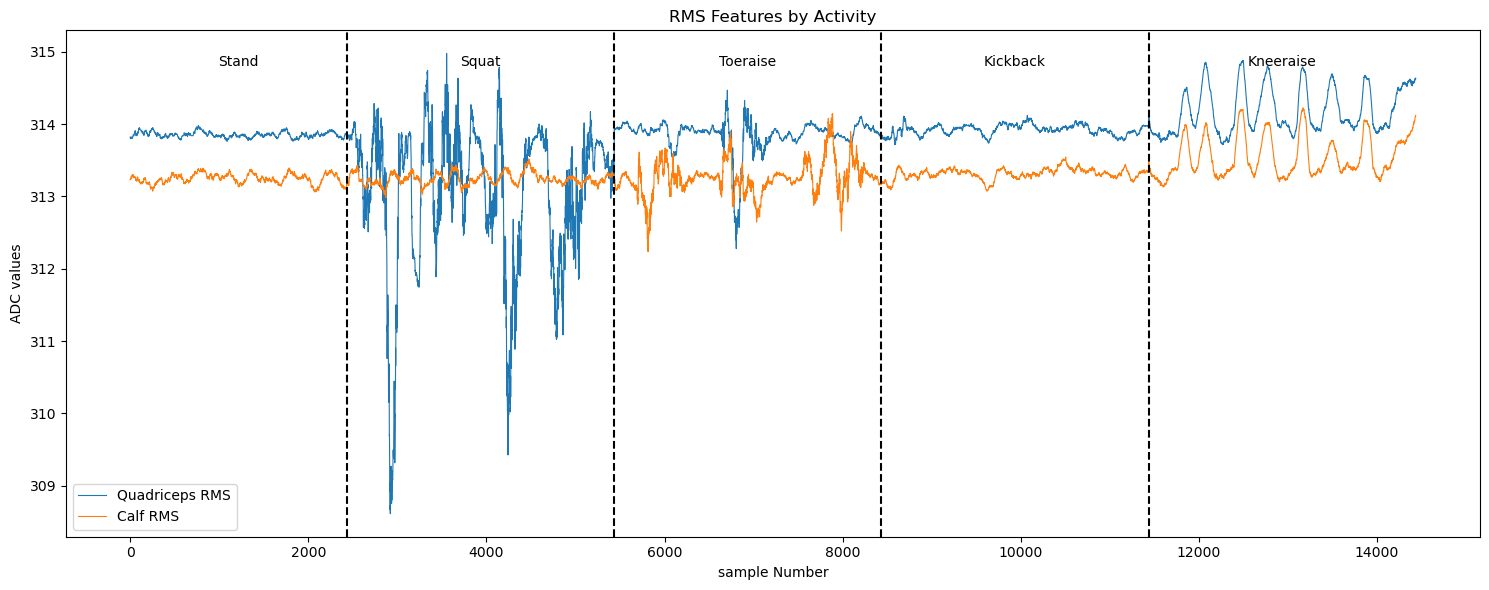

In [24]:
# Reuse the extracted features: columns 0 and 6 contain EMG RMS.
activity_names = ["Stand", "Squat", "Toeraise", "Kickback", "Kneeraise"]
rms_frames = [
    pd.DataFrame(features[n_samples-1000:n_samples*2-1000, [0, 6]], columns=["Quadriceps RMS", "Calf RMS"])
    for features in train_features_per_activity
    ]
df_rms_all = pd.concat(rms_frames, ignore_index=True)
rms_lengths = [len(frame) for frame in rms_frames]
rms_boundaries = np.cumsum(rms_lengths)

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(df_rms_all["Quadriceps RMS"], label="Quadriceps RMS", linewidth=0.8)
ax.plot(df_rms_all["Calf RMS"], label="Calf RMS", linewidth=0.8)

for boundary in rms_boundaries[:-1]:
    ax.axvline(boundary, color="black", linestyle="--")

start = 0
for name, length in zip(activity_names, rms_lengths):
    if length:
        ax.text(
            start + length / 2, 0.93, name,
            transform=ax.get_xaxis_transform(), ha="center"
        )
    start += length

ax.set_title("RMS Features by Activity")
ax.set_xlabel("sample Number")
ax.set_ylabel("ADC values")
ax.legend()
plt.tight_layout()
plt.show()


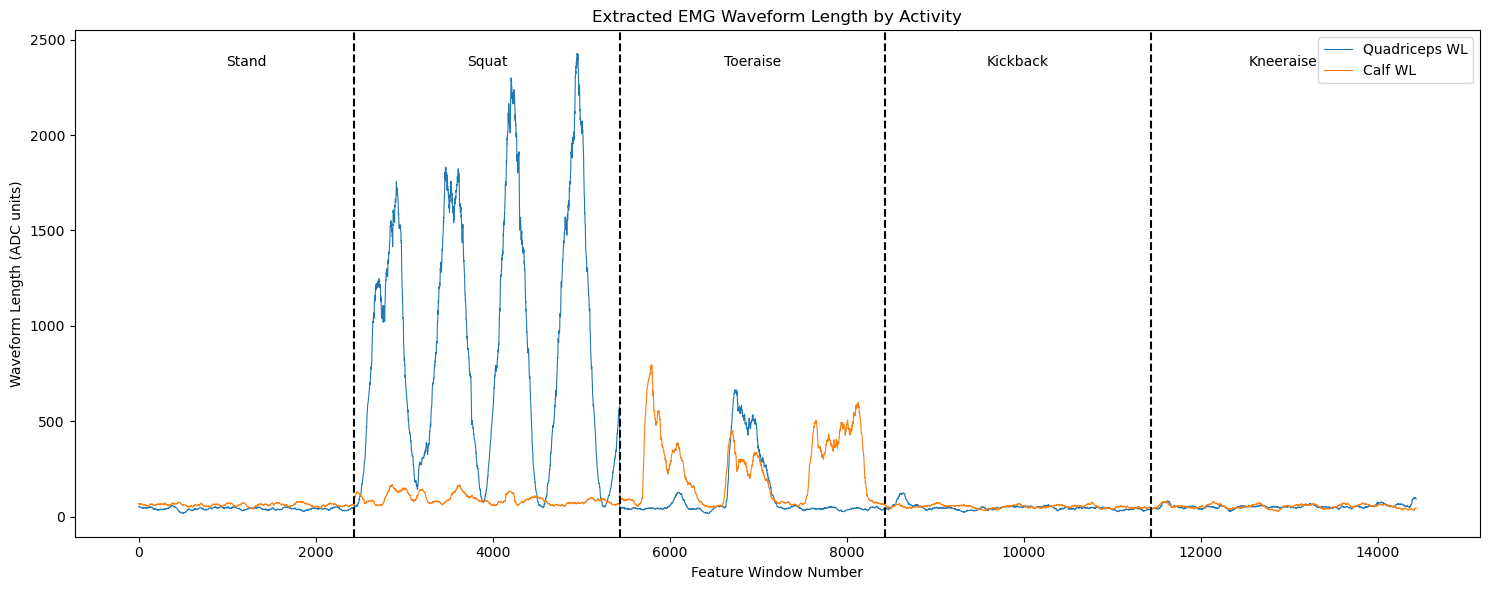

In [25]:
# Reuse extracted waveform length features: quadriceps column 1, calf column 7.
activity_names = ["Stand", "Squat", "Toeraise", "Kickback", "Kneeraise"]
wl_frames = [
    pd.DataFrame(features[n_samples-1000:n_samples*2-1000, [1, 7]], columns=["Quadriceps WL", "Calf WL"])
    for features in train_features_per_activity
]
df_wl_all = pd.concat(wl_frames, ignore_index=True)
wl_lengths = [len(frame) for frame in wl_frames]
wl_boundaries = np.cumsum(wl_lengths)

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(df_wl_all["Quadriceps WL"], label="Quadriceps WL", linewidth=0.8)
ax.plot(df_wl_all["Calf WL"], label="Calf WL", linewidth=0.8)

for boundary in wl_boundaries[:-1]:
    ax.axvline(boundary, color="black", linestyle="--")

start = 0
for name, length in zip(activity_names, wl_lengths):
    if length:
        ax.text(
            start + length / 2, 0.93, name,
            transform=ax.get_xaxis_transform(), ha="center"
        )
    start += length

ax.set_title("Extracted EMG Waveform Length by Activity")
ax.set_xlabel("Feature Window Number")
ax.set_ylabel("Waveform Length (ADC units)")
ax.legend()
plt.tight_layout()
plt.show()


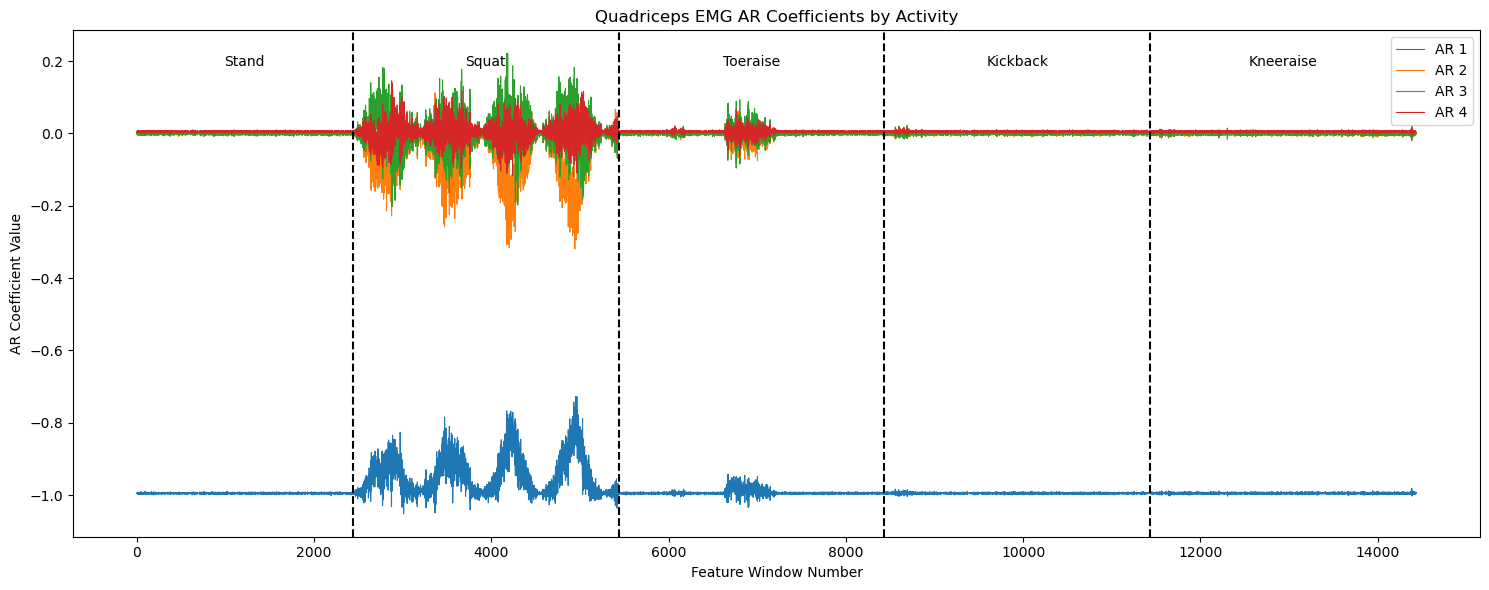

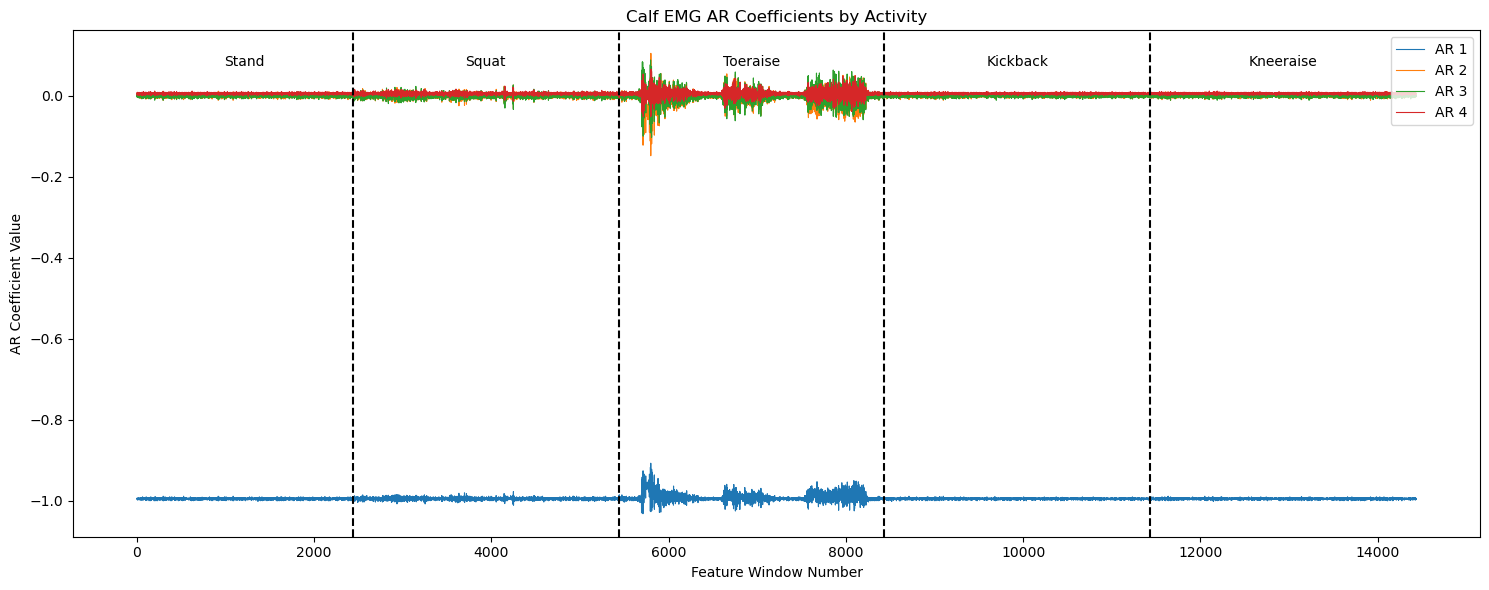

In [28]:
# Reuse extracted AR coefficients: quadriceps columns 2:6, calf columns 8:12.
activity_names = ["Stand", "Squat", "Toeraise", "Kickback", "Kneeraise"]
ar_per_activity = [features[n_samples-1000:n_samples*2-1000] for features in train_features_per_activity]
ar_all = np.vstack(ar_per_activity)
ar_lengths = [len(features) for features in ar_per_activity]
ar_boundaries = np.cumsum(ar_lengths)

for muscle, first_column in [("Quadriceps", 2), ("Calf", 8)]:
    fig, ax = plt.subplots(figsize=(15, 6))

    for coefficient in range(4):
        ax.plot(
            ar_all[:, first_column + coefficient],
            label=f"AR {coefficient + 1}", linewidth=0.8
        )

    for boundary in ar_boundaries[:-1]:
        ax.axvline(boundary, color="black", linestyle="--")

    start = 0
    for name, length in zip(activity_names, ar_lengths):
        if length:
            ax.text(
                start + length / 2, 0.93, name,
                transform=ax.get_xaxis_transform(), ha="center"
            )
        start += length

    ax.set_title(f"{muscle} EMG AR Coefficients by Activity")
    ax.set_xlabel("Feature Window Number")
    ax.set_ylabel("AR Coefficient Value")
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


## Q3

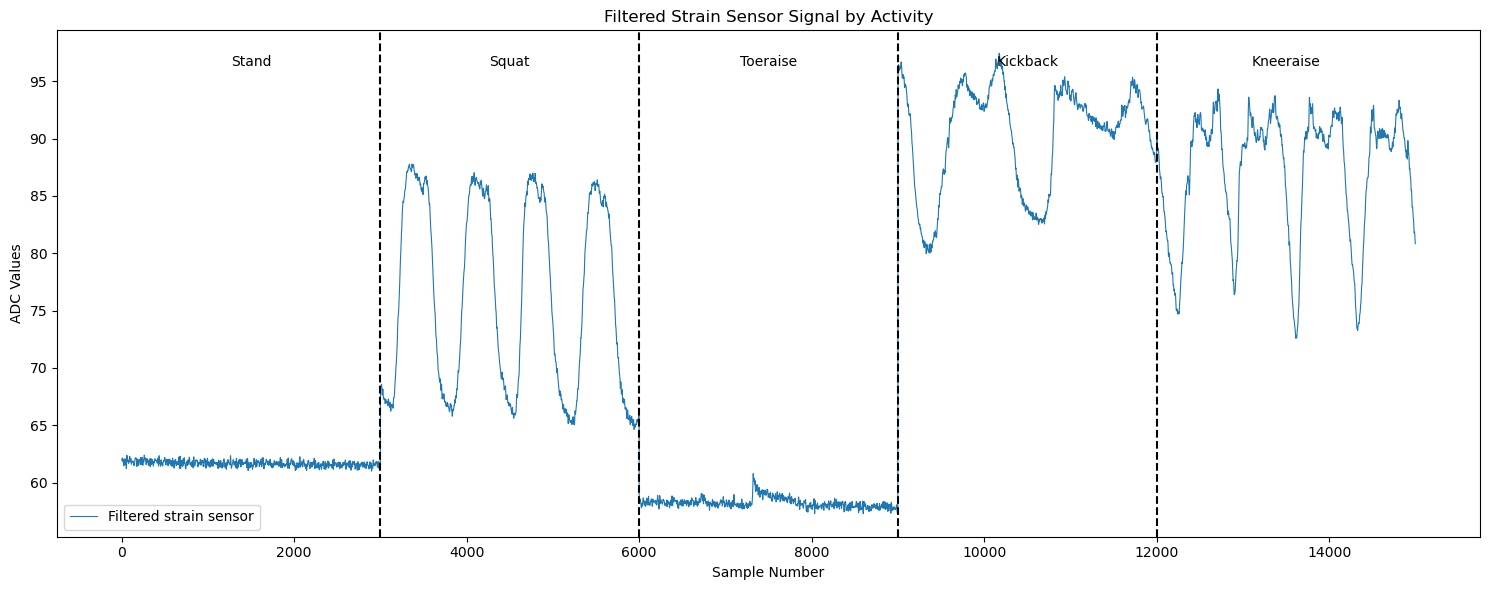

In [29]:
# Reuse the strain signals already filtered with signal.filtfilt above.
# Match the 3000-sample interval used in Q2 for each activity.
activity_names = ["Stand", "Squat", "Toeraise", "Kickback", "Kneeraise"]
n_samples = 3000
strain_short = [
    df.iloc[n_samples-1000:n_samples*2-1000]
    for df in activity_frames
]
df_strain_all = pd.concat(strain_short, ignore_index=True)
strain_lengths = [len(df) for df in strain_short]
strain_boundaries = np.cumsum(strain_lengths)

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(
    df_strain_all["Strain Sensor"],
    label="Filtered strain sensor", linewidth=0.8
)

for boundary in strain_boundaries[:-1]:
    ax.axvline(boundary, color="black", linestyle="--")

start = 0
for name, length in zip(activity_names, strain_lengths):
    if length:
        ax.text(
            start + length / 2, 0.93, name,
            transform=ax.get_xaxis_transform(), ha="center"
        )
    start += length

ax.set_title("Filtered Strain Sensor Signal by Activity")
ax.set_xlabel("Sample Number")
ax.set_ylabel("ADC Values")
ax.legend()
plt.tight_layout()
plt.show()


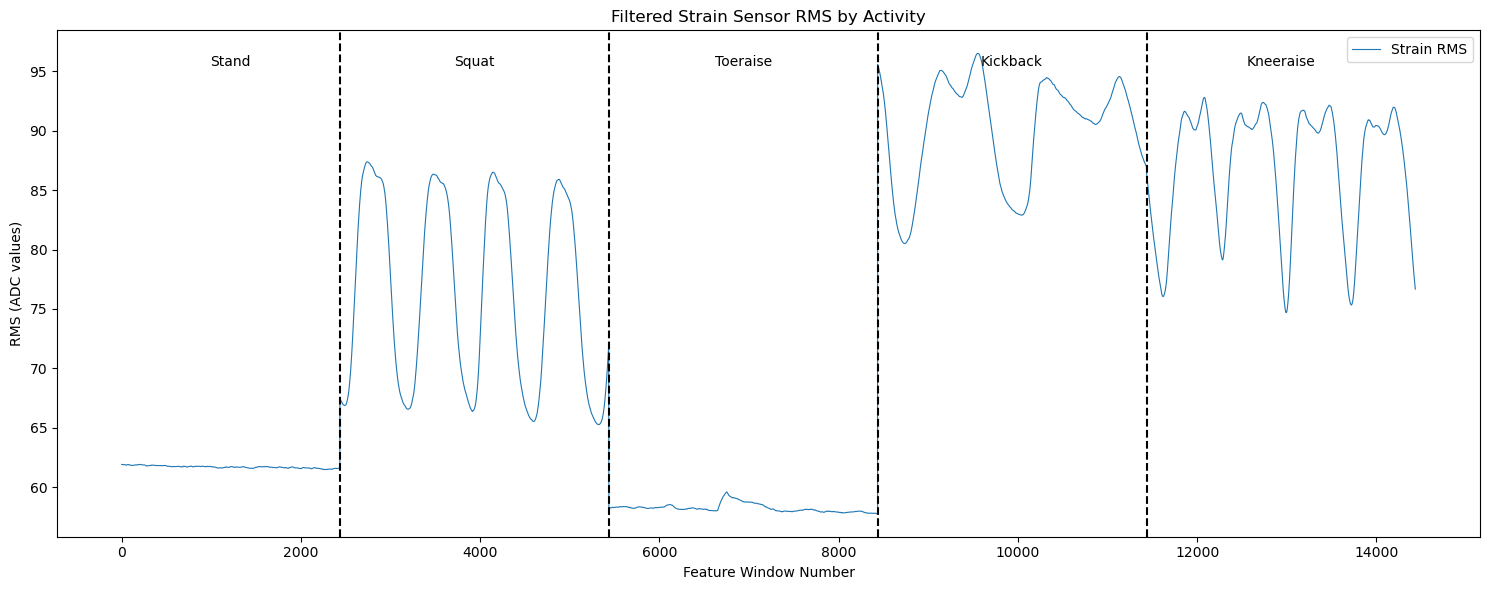

In [30]:
# Reuse extracted strain RMS from feature column 12.
activity_names = ["Stand", "Squat", "Toeraise", "Kickback", "Kneeraise"]
n_samples = 3000
strain_rms_per_activity = [
    features[n_samples-1000:n_samples*2-1000, 12]
    for features in train_features_per_activity
]
strain_rms_all = np.concatenate(strain_rms_per_activity)
strain_rms_lengths = [len(values) for values in strain_rms_per_activity]
strain_rms_boundaries = np.cumsum(strain_rms_lengths)

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(strain_rms_all, label="Strain RMS", linewidth=0.8)

for boundary in strain_rms_boundaries[:-1]:
    ax.axvline(boundary, color="black", linestyle="--")

start = 0
for name, length in zip(activity_names, strain_rms_lengths):
    if length:
        ax.text(
            start + length / 2, 0.93, name,
            transform=ax.get_xaxis_transform(), ha="center"
        )
    start += length

ax.set_title("Filtered Strain Sensor RMS by Activity")
ax.set_xlabel("Feature Window Number")
ax.set_ylabel("RMS (ADC values)")
ax.legend()
plt.tight_layout()
plt.show()


## Q4

In [31]:
def pca(x, n_components):
    mean = np.mean(x, axis=0)
    x_centered = x - mean
    cov_matrix = np.cov(x_centered.T)
    eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)
    idx = np.argsort(eigenvalues)[::-1][:n_components]
    principal_components = eigenvectors[:, idx]
    X_pca = X_centered @ principal_components
    return X_pca, principal_components
